# NLP Laboratory Assignment 3
## Survey and Implementation of Part-of-Speech (POS) Tagging

**Student:** Shravani Kurkute  
**Technique:** Statistical Hidden Markov Model with Viterbi decoding  
**Corpus:** NLTK Penn Treebank, mapped to the NLTK Universal tagset  
**Configuration:** 80:20 sentence-level split, seed 42, add-k transition smoothing (k = 0.001), digit/suffix OOV model

This notebook reproduces the same experiment as `pos_tagging_hmm.py`. Every cell is executable and the saved output corresponds to an actual run.

In [1]:
# 1. Imports and environment setup
import sys, math, json
from collections import Counter
from pathlib import Path

PROJECT_DIR = Path.cwd()
if str(PROJECT_DIR) not in sys.path:
    sys.path.insert(0, str(PROJECT_DIR))

import nltk, numpy as np, pandas as pd, sklearn, matplotlib
from IPython.display import display, Image

import pos_tagging_hmm as pos

pos.set_random_seeds(pos.SEED)
pos.ensure_directories()
print('Project directory :', PROJECT_DIR)
print('Python            :', sys.version.split()[0])
print('NLTK              :', nltk.__version__)
print('NumPy             :', np.__version__)
print('pandas            :', pd.__version__)
print('scikit-learn      :', sklearn.__version__)
print('Matplotlib        :', matplotlib.__version__)
print('Seed              :', pos.SEED)
print('Transition k      :', pos.TRANSITION_K)

Project directory : /home/shravanikurkute/BTech/4th Year/NLP/Assignment 3
Python            : 3.13.9
NLTK              : 3.9.2
NumPy             : 2.2.0
pandas            : 2.2.3
scikit-learn      : 1.6.0
Matplotlib        : 3.10.6
Seed              : 42
Transition k      : 0.001


In [2]:
# 2. Dataset download and loading
resources = pos.ensure_nltk_resources(allow_download=True, verbose=True)
raw_sentences, load_stats = pos.load_treebank_sentences(remove_traces=True)
display(pd.DataFrame(load_stats.items(), columns=['Statistic', 'Value']))
print('First tagged sentence:')
print(raw_sentences[0])

[resources] All required NLTK resources are available.


,Statistic,Value
0,raw_sentences,3914
1,raw_tokens,100676
2,trace_tokens_removed,6592
3,sentences_after_trace_removal,3914
4,tokens_after_trace_removal,94084


First tagged sentence:
[('Pierre', 'NNP'), ('Vinken', 'NNP'), (',', ','), ('61', 'CD'), ('years', 'NNS'), ('old', 'JJ'), (',', ','), ('will', 'MD'), ('join', 'VB'), ('the', 'DT'), ('board', 'NN'), ('as', 'IN'), ('a', 'DT'), ('nonexecutive', 'JJ'), ('director', 'NN'), ('Nov.', 'NNP'), ('29', 'CD'), ('.', '.')]


In [3]:
# 3. Dataset inspection
ptb_tag_counts = Counter(tag for sent in raw_sentences for _, tag in sent)
print('Sentences:', len(raw_sentences))
print('Tokens   :', sum(len(s) for s in raw_sentences))
print('PTB tags :', len(ptb_tag_counts))
display(pd.DataFrame(ptb_tag_counts.most_common(15), columns=['PTB tag', 'Count']))
print('Example with token/PTB-tag format:')
print(' '.join(f'{w}/{t}' for w, t in raw_sentences[1]))

Sentences: 3914
Tokens   : 94084
PTB tags : 45


,PTB tag,Count
0,NN,13166
1,IN,9857
2,NNP,9410
3,DT,8165
4,NNS,6047
5,JJ,5834
6,",",4886
7,.,3874
8,CD,3546
9,VBD,3043


Example with token/PTB-tag format:
Mr./NNP Vinken/NNP is/VBZ chairman/NN of/IN Elsevier/NNP N.V./NNP ,/, the/DT Dutch/NNP publishing/VBG group/NN ./.


In [4]:
# 4. Tagset mapping and train/test split
universal_sentences, tag_mapping = pos.map_ptb_to_universal(raw_sentences)
universal_sentences, duplicates_removed = pos.deduplicate_sentences(universal_sentences)
train_sentences, test_sentences, split_meta = pos.prepare_dataset(
    universal_sentences, test_size=pos.TEST_SIZE, seed=pos.SEED
)
pos.write_sentence_file(PROJECT_DIR / 'train_sentences.txt', train_sentences)
pos.write_sentence_file(PROJECT_DIR / 'test_sentences.txt', test_sentences)
print('Exact duplicate sentences removed:', duplicates_removed)
display(pd.DataFrame(sorted(tag_mapping.items()), columns=['PTB tag', 'Universal tag']))
print('Split:', split_meta)
train_keys = {tuple(s) for s in train_sentences}
test_keys = {tuple(s) for s in test_sentences}
print('Sentence overlap:', len(train_keys & test_keys))
print('First training sentence:')
print(' '.join(w for w, _ in train_sentences[0]))
print('First test sentence:')
print(' '.join(w for w, _ in test_sentences[0]))

Exact duplicate sentences removed: 11


,PTB tag,Universal tag
0,#,.
1,$,.
2,'',.
3,",",.
4,-LRB-,.
5,-RRB-,.
6,.,.
7,:,.
8,CC,CONJ
9,CD,NUM


Split: {'train_sentences': 3122, 'test_sentences': 781, 'train_tokens': 75349, 'test_tokens': 18678, 'split_seed': 42, 'test_size': 0.2, 'sentence_overlap': 0}
Sentence overlap: 0
First training sentence:
Pierre Vinken , 61 years old , will join the board as a nonexecutive director Nov. 29 .
First test sentence:
Mr. Vinken is chairman of Elsevier N.V. , the Dutch publishing group .


In [5]:
# 5. HMM training
hmm = pos.HMMPosTagger(
    transition_k=pos.TRANSITION_K,
    rare_word_threshold=pos.RARE_WORD_THRESHOLD,
    max_suffix_len=pos.MAX_SUFFIX_LEN,
    oov_alpha=pos.OOV_ALPHA,
).train(train_sentences)
baseline = pos.MostFrequentTagBaseline().train(train_sentences)

print('Universal tags      :', hmm.tags)
print('Training vocabulary :', f'{len(hmm.vocab):,}')
print('Emission pairs      :', f'{sum(len(c) for c in hmm.emission_counts.values()):,}')
print('Rare-word occurrences for OOV model:', f'{hmm.rare_token_occurrences:,}')
print('Numeric rare tokens :', f'{hmm.numeric_rare_occurrences:,}')

# Show add-k smoothed transition probabilities from a few frequent tags.
sample_tags = ['DET', 'NOUN', 'VERB', 'ADP', '.']
transition_df = pd.DataFrame(
    {f'{prev} ->': [math.exp(hmm.log_transition[prev][curr]) for curr in sample_tags]
     for prev in [hmm.START, 'DET', 'NOUN', 'VERB']},
    index=sample_tags,
).T
display(transition_df.round(4))

Universal tags      : ['.', 'ADJ', 'ADP', 'ADV', 'CONJ', 'DET', 'NOUN', 'NUM', 'PRON', 'PRT', 'VERB', 'X']
Training vocabulary : 10,625
Emission pairs      : 11,271
Rare-word occurrences for OOV model: 8,929
Numeric rare tokens : 747


,DET,NOUN,VERB,ADP,.
<START> ->,0.2389,0.2905,0.0218,0.1249,0.0846
DET ->,0.0053,0.6363,0.0829,0.0107,0.0175
NOUN ->,0.0143,0.2640,0.1496,0.1797,0.2446
VERB ->,0.1521,0.1305,0.1772,0.1443,0.0753


### 6. Viterbi decoding: explanation

For an HMM, Viterbi computes

$$\delta_i(j) = \max_k \left[\delta_{i-1}(k) + \log P(t_j \mid t_k)\right] + \log P(w_i \mid t_j)$$

and stores $\psi_i(j)=\arg\max_k[\delta_{i-1}(k)+\log P(t_j\mid t_k)]$.
After the final token, $\log P(END\mid t_j)$ is added, the best final tag is selected, and backpointers recover the path. The demonstration below uses the actual trained model and displays the score matrix and chosen predecessor for each position.

In [6]:
# 6. Viterbi decoding demonstration
tokens = ['The', 'committee', 'approved', 'the', 'budget', '.']
tags, log_prob, details = hmm.viterbi_decode(tokens, return_details=True)
print('Tokens     :', tokens)
print('Predicted  :', tags)
print('Log score  :', round(log_prob, 6))
print('Tagged     :', ' '.join(f'{w}/{t}' for w, t in zip(tokens, tags)))

score_df = pd.DataFrame(details['score_matrix'], index=tokens, columns=details['tags'])
display(score_df.round(3))

backpointer_df = pd.DataFrame(
    [[('START' if index < 0 else details['tags'][index]) for index in row]
     for row in details['backpointers']],
    index=tokens,
    columns=details['tags'],
)
print('Chosen predecessor for every (position, tag):')
display(backpointer_df)

Tokens     : ['The', 'committee', 'approved', 'the', 'budget', '.']
Predicted  : ['DET', 'NOUN', 'VERB', 'DET', 'NOUN', '.']
Log score  : -34.395122
Tagged     : The/DET committee/NOUN approved/VERB the/DET budget/NOUN ./.


,.,ADJ,ADP,ADV,CONJ,DET,NOUN,NUM,PRON,PRT,VERB,X
The,-inf,-inf,-inf,-inf,-inf,-3.940,-10.587,-inf,-inf,-inf,-inf,-inf
committee,-inf,-inf,-inf,-inf,-inf,-inf,-11.871,-inf,-inf,-inf,-inf,-inf
approved,-inf,-inf,-inf,-inf,-inf,-inf,-inf,-inf,-inf,-inf,-20.175,-inf
the,-inf,-29.969,-inf,-inf,-inf,-22.829,-32.255,-31.882,-inf,-inf,-inf,-inf
budget,-inf,-inf,-inf,-inf,-inf,-inf,-30.760,-inf,-inf,-inf,-inf,-inf
.,-33.289,-inf,-inf,-inf,-inf,-inf,-inf,-inf,-inf,-inf,-inf,-inf


Chosen predecessor for every (position, tag):


,.,ADJ,ADP,ADV,CONJ,DET,NOUN,NUM,PRON,PRT,VERB,X
The,START,START,START,START,START,START,START,START,START,START,START,START
committee,START,START,START,START,START,START,DET,START,START,START,START,START
approved,START,START,START,START,START,START,START,START,START,START,NOUN,START
the,START,VERB,START,START,START,VERB,VERB,VERB,START,START,START,START
budget,START,START,START,START,START,START,DET,START,START,START,START,START
.,NOUN,START,START,START,START,START,START,START,START,START,START,START


In [7]:
# 7. Baseline comparison
test_words, test_tags = pos.flatten_tagged(test_sentences)
train_words, train_tags = pos.flatten_tagged(train_sentences)
train_vocab = set(train_words)

hmm_predictions = [hmm.tag([w for w, _ in sent]) for sent in test_sentences]
baseline_predictions = [baseline.tag([w for w, _ in sent]) for sent in test_sentences]
y_true = pos.flatten_predictions([[t for _, t in sent] for sent in test_sentences])
y_hmm = pos.flatten_predictions(hmm_predictions)
y_base = pos.flatten_predictions(baseline_predictions)

hmm_metrics, hmm_per_tag, cm = pos.evaluate_tags(y_true, y_hmm, hmm.tags, test_words, train_vocab)
base_metrics, base_per_tag, _ = pos.evaluate_tags(y_true, y_base, hmm.tags, test_words, train_vocab)

comparison_df = pd.DataFrame({
    'Metric': ['Accuracy', 'Macro Precision', 'Macro Recall', 'Macro F1',
               'Weighted Precision', 'Weighted Recall', 'Weighted F1',
               'OOV Accuracy', 'Known Accuracy'],
    'Baseline': [base_metrics['accuracy'], base_metrics['macro_precision'], base_metrics['macro_recall'],
                 base_metrics['macro_f1'], base_metrics['weighted_precision'], base_metrics['weighted_recall'],
                 base_metrics['weighted_f1'], base_metrics['oov_accuracy'], base_metrics['known_accuracy']],
    'HMM': [hmm_metrics['accuracy'], hmm_metrics['macro_precision'], hmm_metrics['macro_recall'],
            hmm_metrics['macro_f1'], hmm_metrics['weighted_precision'], hmm_metrics['weighted_recall'],
            hmm_metrics['weighted_f1'], hmm_metrics['oov_accuracy'], hmm_metrics['known_accuracy']],
})
comparison_df['Difference'] = comparison_df['HMM'] - comparison_df['Baseline']
display(comparison_df.round(6))

,Metric,Baseline,HMM,Difference
0,Accuracy,0.932594,0.953475,0.020880
1,Macro Precision,0.876046,0.960539,0.084492
2,Macro Recall,0.841494,0.899935,0.058441
3,Macro F1,0.856378,0.916128,0.059749
4,Weighted Precision,0.935462,0.953045,0.017584
5,Weighted Recall,0.932594,0.953475,0.020880
6,Weighted F1,0.931416,0.953004,0.021588
7,OOV Accuracy,0.536469,0.755965,0.219496
8,Known Accuracy,0.966359,0.970310,0.003951


In [8]:
# 8. Evaluation metrics and per-tag report
display(hmm_per_tag.round(4))
print('HMM classification report:')
print(hmm_metrics['classification_report'])
print('Test tokens:', hmm_metrics['support'])
print('OOV tokens :', hmm_metrics['oov_count'], f"({hmm_metrics['oov_rate']*100:.2f}%)")
print('HMM OOV accuracy     :', round(hmm_metrics['oov_accuracy'], 6))
print('HMM known accuracy   :', round(hmm_metrics['known_accuracy'], 6))

,tag,precision,recall,f1_score,support
0,.,0.9949,0.9996,0.9972,2338
1,ADJ,0.8881,0.8025,0.8431,1296
2,ADP,0.9501,0.9701,0.9600,1943
3,ADV,0.8891,0.8863,0.8877,651
4,CONJ,0.9883,0.9906,0.9895,427
5,DET,0.9561,0.9703,0.9631,1683
6,NOUN,0.9469,0.9680,0.9573,5836
7,NUM,0.9956,0.9898,0.9927,683
8,PRON,0.9962,0.9981,0.9972,526
9,PRT,0.9738,0.9691,0.9714,614


HMM classification report:
              precision    recall  f1-score   support

           .     0.9949    0.9996    0.9972      2338
         ADJ     0.8881    0.8025    0.8431      1296
         ADP     0.9501    0.9701    0.9600      1943
         ADV     0.8891    0.8863    0.8877       651
        CONJ     0.9883    0.9906    0.9895       427
         DET     0.9561    0.9703    0.9631      1683
        NOUN     0.9469    0.9680    0.9573      5836
         NUM     0.9956    0.9898    0.9927       683
        PRON     0.9962    0.9981    0.9972       526
         PRT     0.9738    0.9691    0.9714       614
        VERB     0.9474    0.9216    0.9343      2678
           X     1.0000    0.3333    0.5000         3

    accuracy                         0.9535     18678
   macro avg     0.9605    0.8999    0.9161     18678
weighted avg     0.9530    0.9535    0.9530     18678

Test tokens: 18678
OOV tokens : 1467 (7.85%)
HMM OOV accuracy     : 0.755965
HMM known accuracy   : 0.9703

In [9]:
# 9. Custom sentence predictions (previously unseen)
custom_sentences = pos.load_custom_sentences(PROJECT_DIR / 'custom_test_sentences.txt')
custom_records, custom_rows = pos.run_custom_tests(custom_sentences, hmm, baseline)
for record in custom_records:
    print(f"{record['sentence_id']:02d}. {record['sentence']}")
    print('    HMM     :', record['hmm_tagged'])
    print('    Baseline:', record['baseline_tagged'])
    print()

01. The quick brown fox jumps over the lazy dog.
    HMM     : The/DET quick/ADJ brown/NOUN fox/ADP jumps/NOUN over/ADP the/DET lazy/ADJ dog/NOUN ./.
    Baseline: The/DET quick/ADJ brown/NOUN fox/NOUN jumps/NOUN over/ADP the/DET lazy/NOUN dog/NOUN ./.

02. Shravani is studying Natural Language Processing at her university.
    HMM     : Shravani/NOUN is/VERB studying/VERB Natural/NOUN Language/NOUN Processing/NOUN at/ADP her/PRON university/NOUN ./.
    Baseline: Shravani/NOUN is/VERB studying/VERB Natural/NOUN Language/NOUN Processing/NOUN at/ADP her/PRON university/NOUN ./.

03. The committee approved the new budget after a long discussion.
    HMM     : The/DET committee/NOUN approved/VERB the/DET new/ADJ budget/NOUN after/ADP a/DET long/ADJ discussion/NOUN ./.
    Baseline: The/DET committee/NOUN approved/VERB the/DET new/ADJ budget/NOUN after/ADP a/DET long/ADJ discussion/NOUN ./.

04. She bought three apples and two oranges at the market.
    HMM     : She/PRON bought/VERB three

In [10]:
# 10. Error analysis
error_rows, top_errors = pos.build_error_rows(
    test_sentences, hmm_predictions, baseline_predictions, train_vocab
)
print('Total HMM token errors:', len(error_rows))
top_error_df = pd.DataFrame(top_errors[:10])
display(top_error_df)
print('First five error contexts:')
for row in error_rows[:5]:
    print('-', row['context'])

Total HMM token errors: 869


,gold_tag,predicted_tag,count,percentage_of_errors,example_context
0,VERB,NOUN,152,17.491369,", the Dutch [publishing/VERB->NOUN] group ."
1,ADJ,NOUN,143,16.455696,"regulation for the [smooth/ADJ->NOUN] , needle..."
2,NOUN,VERB,76,8.745685,", even though [exhaust/NOUN->VERB] fans ventil..."
3,NOUN,ADJ,75,8.630610,"N.V. , the [Dutch/NOUN->ADJ] publishing group ."
4,ADJ,VERB,55,6.329114,maturity for funds [open/ADJ->VERB] only to in...
5,DET,ADP,41,4.718067,few industrialized nations [that/DET->ADP] doe...
6,ADJ,ADV,31,3.567319,Shearson Lehman Hutton [earlier/ADJ->ADV] this...
7,ADV,ADJ,31,3.567319,in dollar-denominated securities [overseas/ADV...
8,ADP,ADV,26,2.991945,talking about years [ago/ADP->ADV] before anyo...
9,VERB,ADP,21,2.416571,[Knowing/VERB->ADP] a tasty --


First five error contexts:
- is chairman of [Elsevier/NOUN->DET] N.V. , the
- N.V. , the [Dutch/NOUN->ADJ] publishing group .
- , the Dutch [publishing/VERB->NOUN] group .
- talking about years [ago/ADP->ADV] before anyone heard
- in the early [1950s/NUM->NOUN] and replaced with


visualizations/confusion_matrix.png


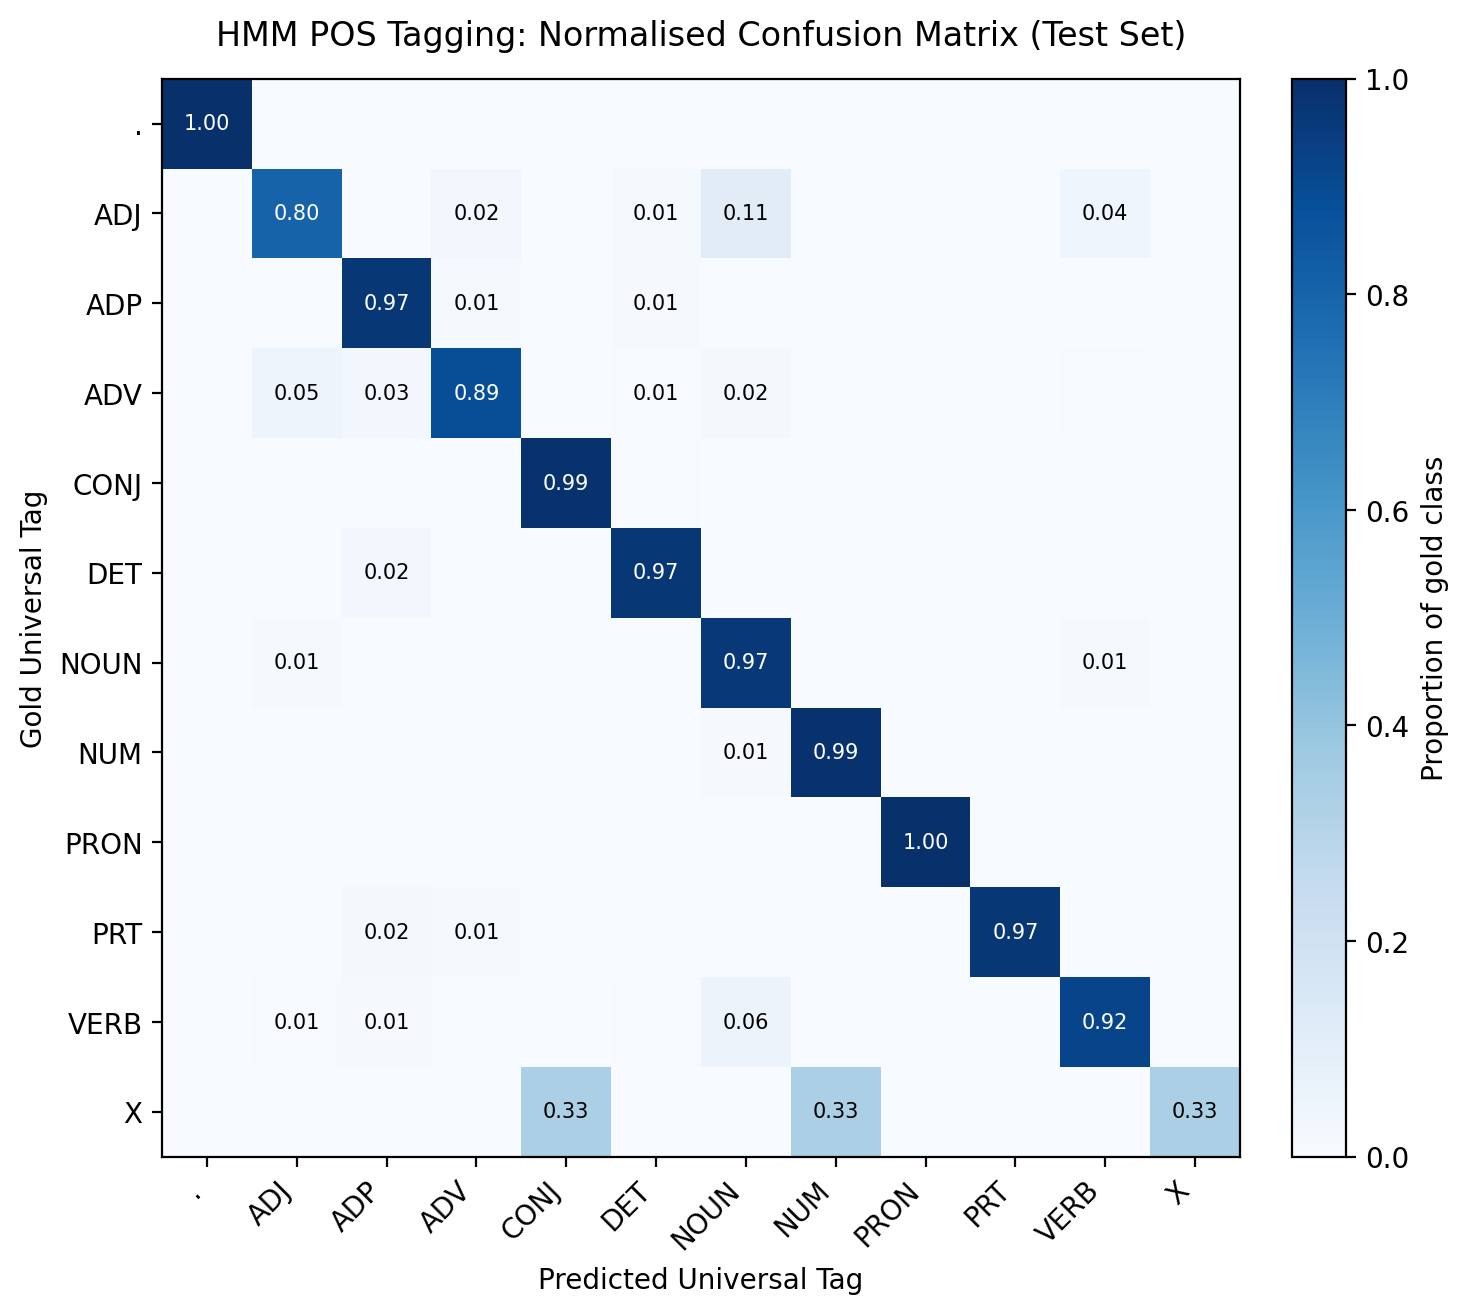

visualizations/per_tag_scores.png


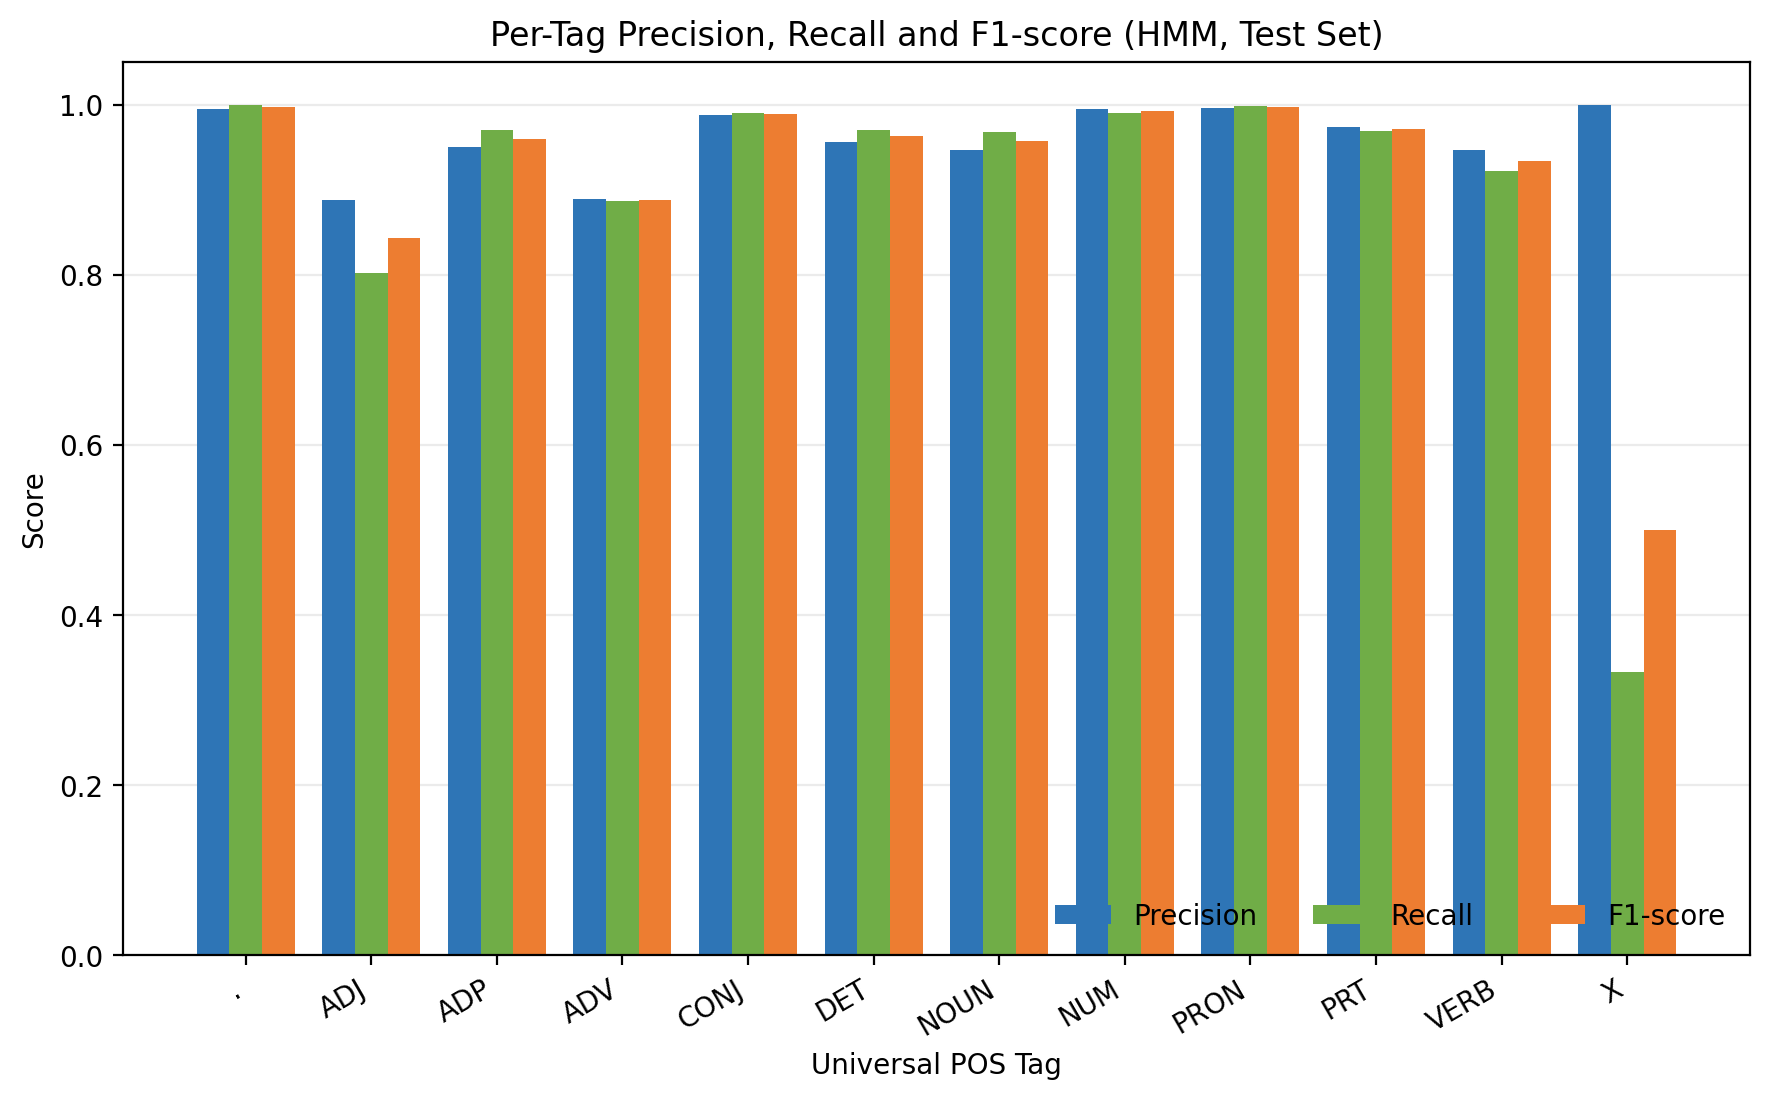

visualizations/model_comparison.png


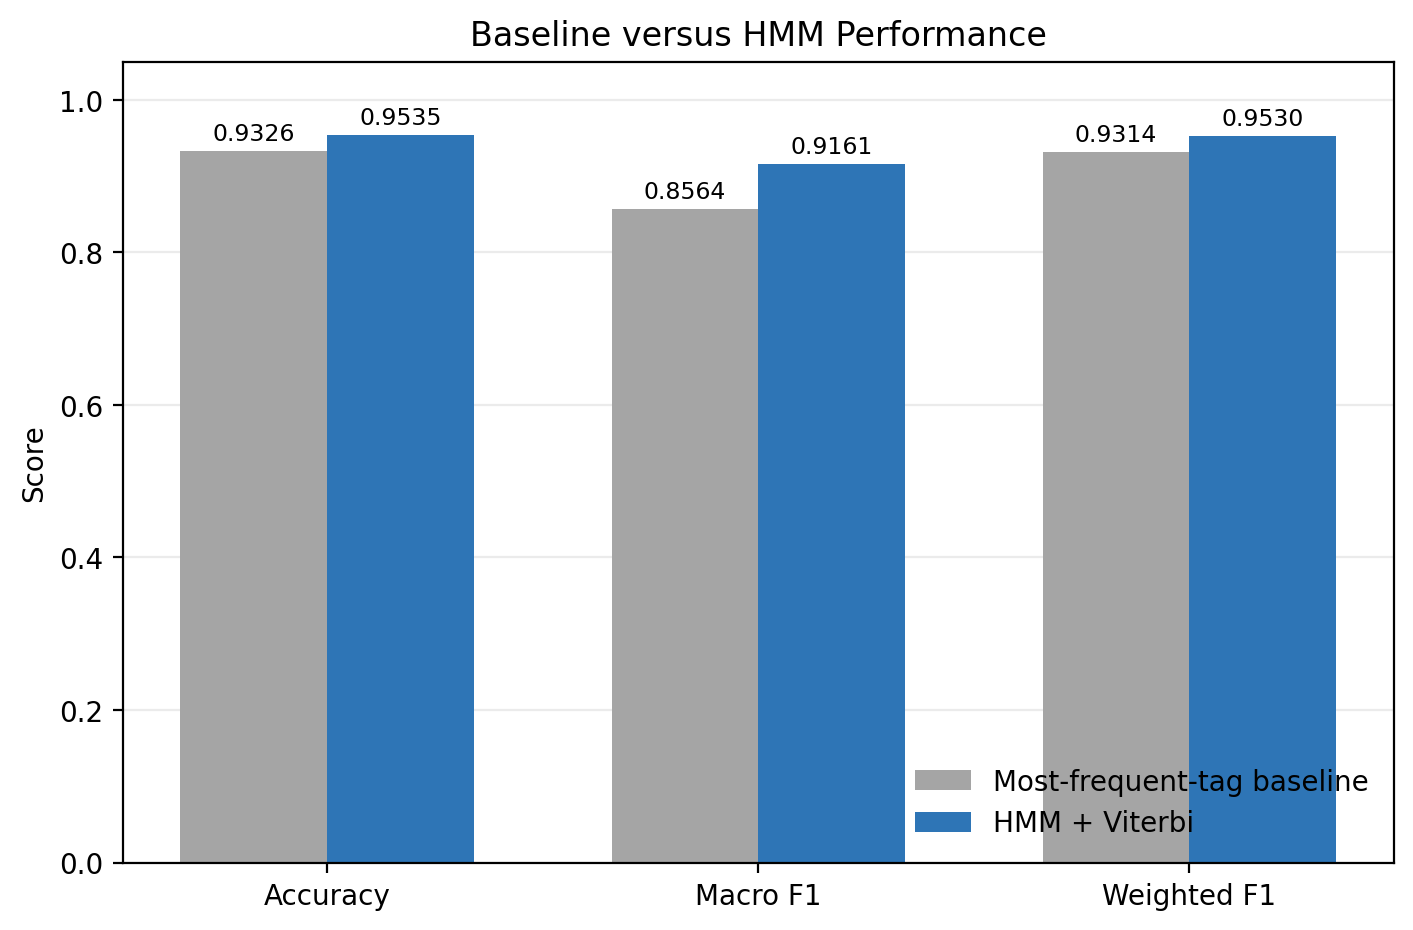

visualizations/oov_analysis.png


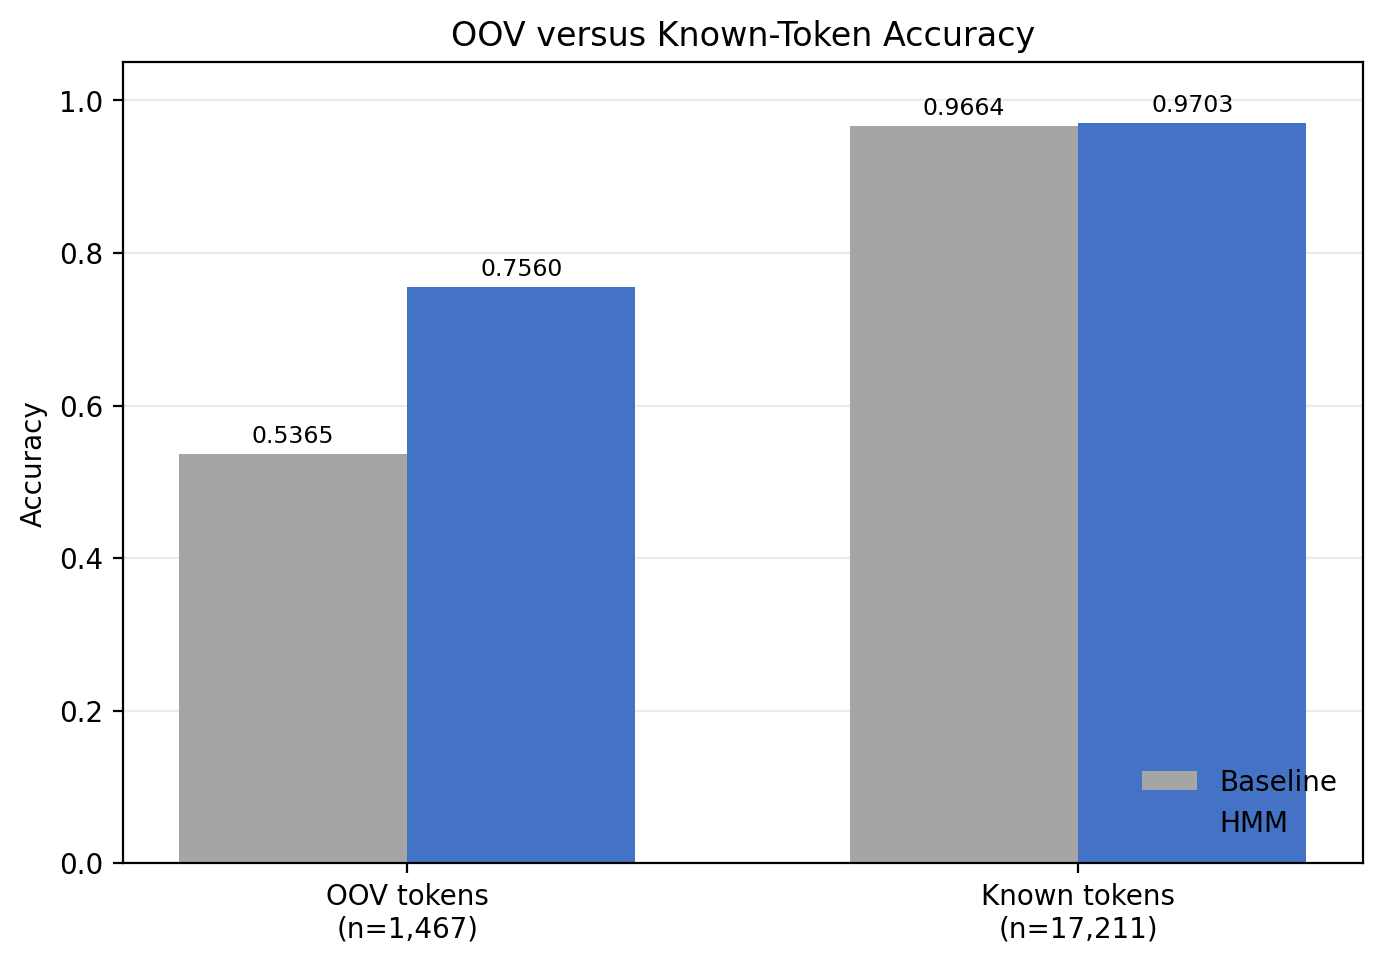

visualizations/tag_distribution.png


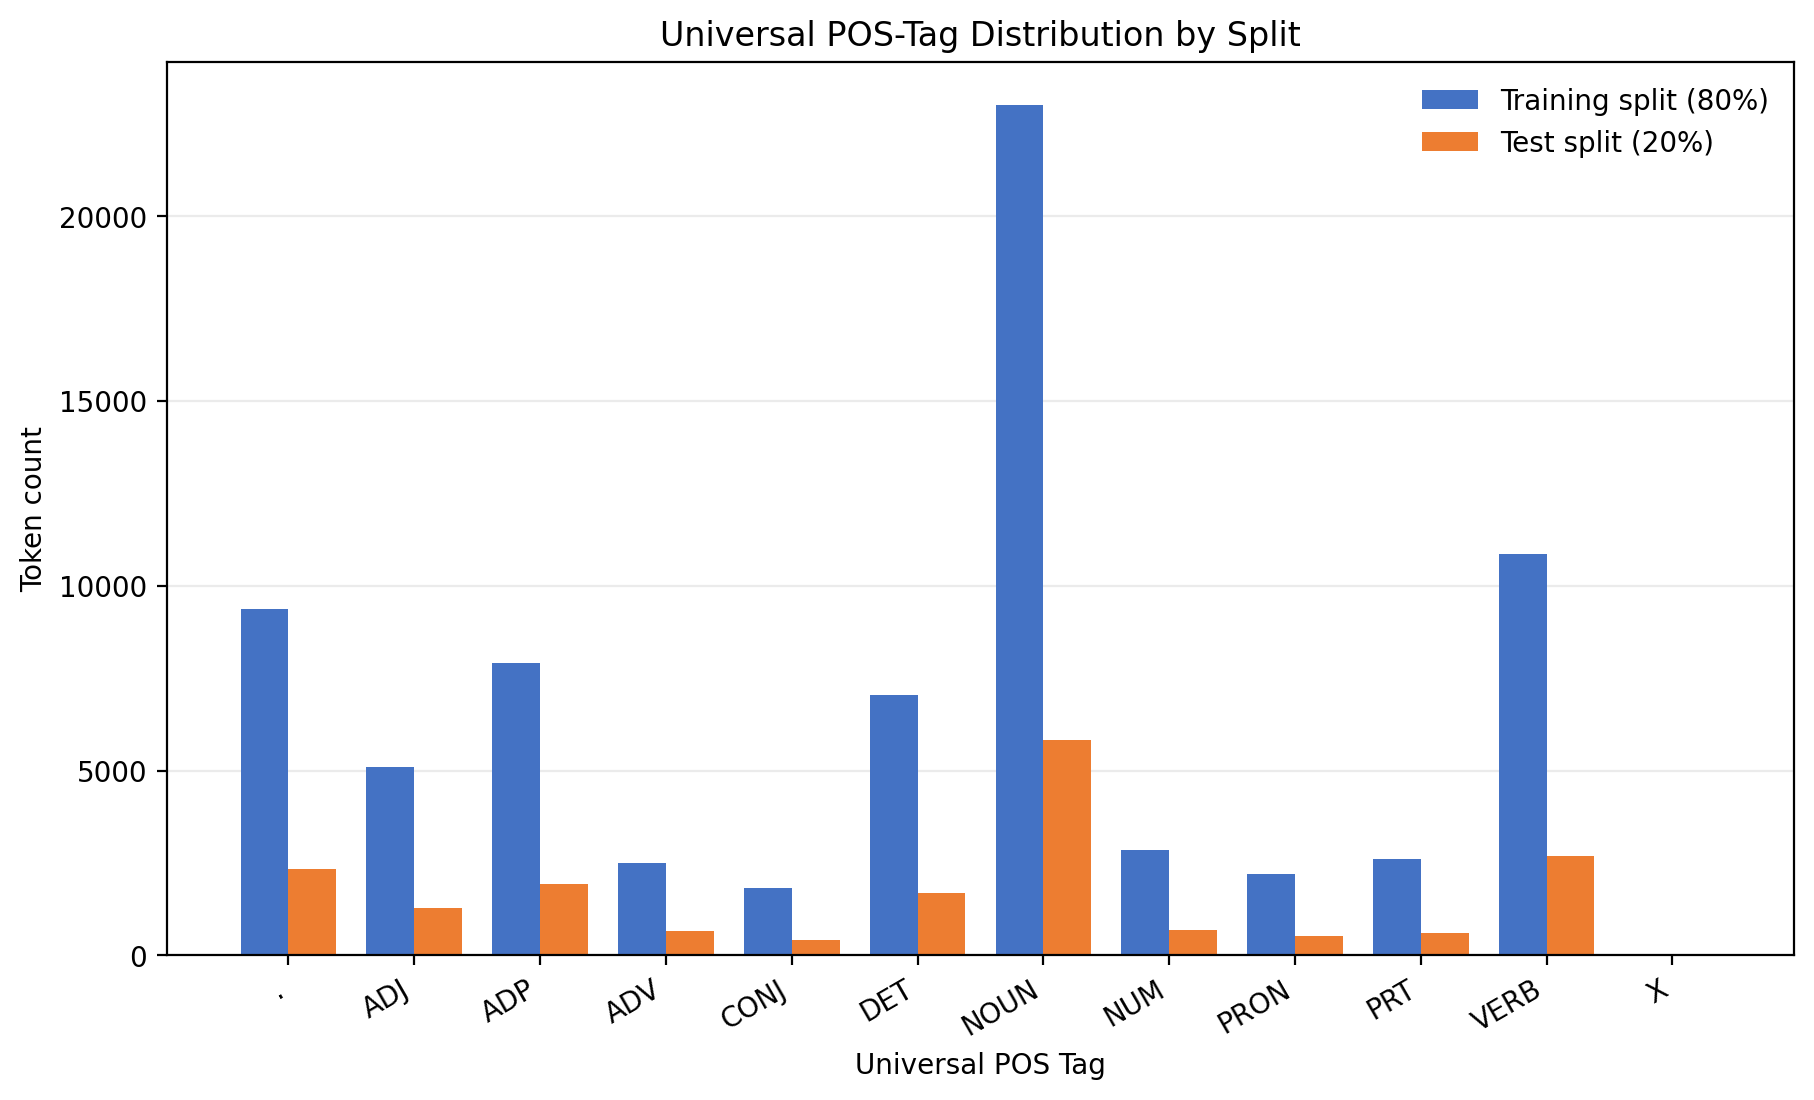

In [11]:
# 11. Visualizations (regenerated from the same configuration)
bundle = pos.run_pipeline(write_files=False, verbose=False)
result = bundle['result']
charts = pos.generate_visualizations(result, bundle['y_true'], bundle['y_pred'])
for chart in charts:
    print(chart)
    display(Image(filename=str(PROJECT_DIR / chart), width=820))

In [12]:
# 12. Saving results and validating outputs
created = pos.save_core_outputs(bundle)
print('Files written:')
for item in created:
    print(' -', item)
required = [
    'results.json', 'evaluation_results.csv', 'sample_tagged_output.csv',
    'error_analysis.csv', 'train_sentences.txt', 'test_sentences.txt',
    'custom_test_sentences.txt', 'visualizations/confusion_matrix.png',
    'visualizations/per_tag_scores.png', 'visualizations/model_comparison.png',
    'visualizations/oov_analysis.png', 'visualizations/tag_distribution.png',
]
for relative in required:
    assert (PROJECT_DIR / relative).exists(), relative
print('All required core artefacts exist.')
display(pd.DataFrame(result['summary']))

Files written:
 - train_sentences.txt
 - test_sentences.txt
 - custom_test_sentences.txt
 - evaluation_results.csv
 - sample_tagged_output.csv
 - error_analysis.csv
 - custom_predictions.csv
 - results.json
 - visualizations/confusion_matrix.png
 - visualizations/per_tag_scores.png
 - visualizations/model_comparison.png
 - visualizations/oov_analysis.png
 - visualizations/tag_distribution.png
All required core artefacts exist.


,metric,value
0,Corpus,NLTK Penn Treebank (treebank.tagged_sents())
1,Universal tagset size,12
2,Prepared sentences,3903
3,Training sentences,3122
4,Test sentences,781
5,Training tokens,75349
6,Test tokens,18678
7,Test OOV tokens,1467
8,Baseline accuracy,0.932594
9,HMM accuracy,0.953475
